# 05.b - Concentração da infraestrutura DNS por bloco econômico

Compara **EUA**, **União Europeia (UE-27)** e **BRICS (composição oficial 2026)** - mais um grupo residual **Outros** -
na concentração de provedores de infraestrutura (`as_org` = rede que hospeda os NS; `ns_apex` = operador do DNS).

Cada análise é feita com **duas ponderações**:

- **empresas**: cada empresa pesa 1;
- **receita**: cada empresa pesa `revenue_ttm`.

**Convenções**

- *Dependência* = par (empresa, provedor), deduplicado: uma empresa com 4 NS na mesma organização conta uma vez.
- *Participação* (usada no HHI) = fatia do provedor no total de dependências do grupo.
- *Cobertura* = % das empresas (ou da receita) do grupo que usam o provedor. Somam mais de 100% porque a empresa pode usar vários.
- O bloco da empresa vem de `company_country` (país de listagem no ranking); o bloco do provedor vem de `as_country_code` (país de registro da organização).

**Seções**: 1 Blocos e cobertura · 2 Concentração (HHI, CR, N efetivo, IC bootstrap) · 3 Principais provedores · 4 Curvas de concentração ·
5 Jurisdição / soberania · 6 Setor × bloco · 7 Porte × bloco · 8 Resiliência · 9 Empresas vs receita · 10 IPv4 vs IPv6 · 11 DNS vs hosting · 12 Resumo

In [25]:
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Caminhos
DATA_INTERIM = Path("../data/interim")
OUT = Path("../data/analysis/blocs")
FIG = OUT / "figs"
FIG.mkdir(parents=True, exist_ok=True)

# --- Parâmetros da análise
FAMILY = "A"                      # "A" = IPv4 (base principal) | "AAAA" = IPv6
LAYER = "as_org"                  # camada principal: "as_org" (hosting/rede) | "ns_apex" (operador DNS)
MIN_N = 30                        # nº mínimo de empresas para publicar um recorte (setor x bloco etc.)
N_BOOT = 500                      # reamostragens para o intervalo de confiança do HHI
SEED = 42
SAUDI_IS_BRICS_MEMBER = False     # Arábia Saudita foi convidada, mas não formalizou adesão
HK_MACAU_AS_CHINA = False         # Hong Kong / Macau como parte da China (False = ficam em Outros)

In [26]:
# --- Estilo (cores fixas por entidade; a mesma cor representa o mesmo bloco em todos os gráficos)
BLOC_ORDER = ["EUA", "UE", "BRICS", "Outros"]
BLOC_COLOR = {"EUA": "#2a78d6", "UE": "#eb6834", "BRICS": "#1baf7a", "Outros": "#8a8985",
              "Desconhecido": "#c3c2b7", "Global": "#52514e"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#e8f1fc", "#86b6ef", "#2a78d6", "#0d366b"])

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.facecolor": "white", "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "font.size": 10, "legend.frameon": False,
})


def show(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def trunc(s, n=30):
    s = str(s)
    return s if len(s) <= n else s[: n - 1] + "…"

## 1. Definição dos blocos

- **BRICS (membros plenos, 2026)**: Brasil, Rússia, Índia, China, África do Sul, Egito, Etiópia, Irã, Emirados Árabes Unidos e Indonésia.
  Países parceiros (Belarus, Cazaquistão, Malásia, Tailândia, Vietnã etc.) **não** entram. Os dois parâmetros acima tratam os casos ambíguos.
- **UE**: os 27 Estados-membros atuais.
- **EUA**: Estados Unidos.
- **Outros**: todo o restante (inclui Reino Unido, Japão, Suíça, Canadá, paraísos fiscais, etc.).

Os blocos são mutuamente exclusivos.

In [27]:
BRICS_NAMES = ["Brazil", "Russia", "India", "China", "South Africa", "Egypt", "Ethiopia", "Iran",
               "United Arab Emirates", "Indonesia"]
BRICS_ISO = ["BR", "RU", "IN", "CN", "ZA", "EG", "ET", "IR", "AE", "ID"]
if SAUDI_IS_BRICS_MEMBER:
    BRICS_NAMES.append("Saudi Arabia"); BRICS_ISO.append("SA")
if HK_MACAU_AS_CHINA:
    BRICS_NAMES += ["Hong Kong", "Macau"]; BRICS_ISO += ["HK", "MO"]

EU_NAMES = ["Austria", "Belgium", "Bulgaria", "Croatia", "Cyprus", "Czech Republic", "Denmark", "Estonia", "Finland",
            "France", "Germany", "Greece", "Hungary", "Ireland", "Italy", "Latvia", "Lithuania", "Luxembourg", "Malta",
            "Netherlands", "Poland", "Portugal", "Romania", "Slovakia", "Slovenia", "Spain", "Sweden"]
EU_ISO = ["AT", "BE", "BG", "HR", "CY", "CZ", "DK", "EE", "FI", "FR", "DE", "GR", "HU", "IE", "IT", "LV", "LT", "LU",
          "MT", "NL", "PL", "PT", "RO", "SK", "SI", "ES", "SE"]
assert len(EU_NAMES) == len(EU_ISO) == 27

bloc_of_name = {**{n: "BRICS" for n in BRICS_NAMES}, **{n: "UE" for n in EU_NAMES}, "United States": "EUA"}
bloc_of_iso = {**{c: "BRICS" for c in BRICS_ISO}, **{c: "UE" for c in EU_ISO}, "US": "EUA"}

# --- Dados
raw = pd.read_parquet(DATA_INTERIM / "full_resolved_clean_depara.parquet")
#raw = pd.read_parquet(DATA_INTERIM / "full_resolved_clean.parquet")
raw["bloc"] = raw["company_country"].map(bloc_of_name).fillna("Outros")

comp = (raw.drop_duplicates("rank")
           [["rank", "company_name", "ticker_symbol", "company_country", "sector", "industry", "revenue_ttm", "bloc"]]
           .set_index("rank"))
print(f"{len(raw)} linhas | {len(comp)} empresas resolvidas | família principal: {FAMILY} | camada: {LAYER}")

# países do bloco que não aparecem na amostra (cobertura da definição)
present = set(comp["company_country"])
print("Membros BRICS sem nenhuma empresa na amostra:", sorted(set(BRICS_NAMES) - present))
print("Membros UE sem nenhuma empresa na amostra   :", sorted(set(EU_NAMES) - present))

83539 linhas | 10635 empresas resolvidas | família principal: A | camada: as_org
Membros BRICS sem nenhuma empresa na amostra: ['Ethiopia', 'Iran', 'Russia']
Membros UE sem nenhuma empresa na amostra   : ['Croatia', 'Slovakia', 'Slovenia']


In [28]:
def build_dep(family=FAMILY, layer=LAYER):
    # uma linha por dependência (empresa, provedor), com o bloco da empresa e o bloco/jurisdição do provedor
    d = raw[(raw["ip_type"] == family) & raw["as_org"].notna()].copy()
    d["unit"] = d[layer]
    d = d[d["unit"].notna()]
    cc = (d.groupby("unit")["as_country_code"]
            .agg(lambda s: s.mode().iat[0] if s.notna().any() else np.nan))   # país predominante do provedor
    d = d.drop_duplicates(["rank", "unit"])[["rank", "unit", "bloc", "sector", "revenue_ttm"]].copy()
    d["provider_cc"] = d["unit"].map(cc)
    pb = d["provider_cc"].map(bloc_of_iso).fillna("Outros")
    pb[d["provider_cc"].isna()] = "Desconhecido"
    d["provider_bloc"] = pb
    return d


_dep_cache = {}


def dep_for(family=FAMILY, layer=LAYER):
    if (family, layer) not in _dep_cache:
        _dep_cache[(family, layer)] = build_dep(family, layer)
    return _dep_cache[(family, layer)]


dep = dep_for()
comp_in = comp.loc[dep["rank"].unique()]          # empresas com ao menos 1 dependência na família escolhida

# --- Tabela 1: composição da amostra por bloco
t1 = comp_in.groupby("bloc").agg(empresas=("revenue_ttm", "size"), receita=("revenue_ttm", "sum")).reindex(BLOC_ORDER)
t1["% empresas"] = t1["empresas"] / t1["empresas"].sum() * 100
t1["% receita"] = t1["receita"] / t1["receita"].sum() * 100
t1["provedores distintos"] = dep.groupby("bloc")["unit"].nunique().reindex(BLOC_ORDER)
t1["receita (US$ tri)"] = t1["receita"] / 1e12
t1 = t1.drop(columns="receita")
t1.round(1)

,empresas,% empresas,% receita,provedores distintos,receita (US$ tri)
bloc,,,,,
EUA,3245,31.7,37.3,260,24.7
UE,1780,17.4,16.0,394,10.6
BRICS,1281,12.5,15.9,177,10.5
Outros,3944,38.5,30.9,453,20.5


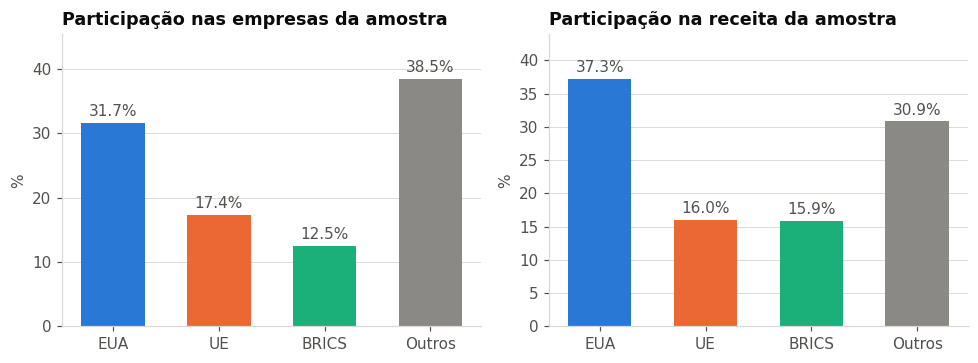

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, col, ttl in zip(axes, ["% empresas", "% receita"], ["Participação nas empresas da amostra", "Participação na receita da amostra"]):
    v = t1[col].reindex(BLOC_ORDER)
    ax.bar(BLOC_ORDER, v, color=[BLOC_COLOR[b] for b in BLOC_ORDER], width=0.6)
    for i, x in enumerate(v):
        ax.text(i, x + 1, f"{x:.1f}%", ha="center", color=INK2)
    ax.set_title(ttl); ax.set_ylim(0, v.max() * 1.18); ax.set_ylabel("%"); ax.grid(axis="x", visible=False)
show(fig, "01_composicao_blocos")

## 2. Concentração por bloco

Métricas: **HHI** (0-10.000), **CR1/CR4/CR10** (soma das maiores participações), **N efetivo** = 10.000/HHI
(nº de provedores igualmente grandes que gerariam o mesmo HHI) e **entropia normalizada** (0 = um provedor, 1 = uniforme).
O intervalo de confiança vem de *bootstrap* reamostrando **empresas** dentro de cada bloco.

In [30]:
def weights_series(d, weight):
    # total por provedor: nº de empresas ou soma de receita (d já está deduplicado por empresa-provedor)
    if weight == "empresas":
        return d.groupby("unit")["rank"].nunique()
    return d.groupby("unit")["revenue_ttm"].sum()


def shares(d, weight):
    s = weights_series(d, weight)
    s = s[s > 0]
    return (s / s.sum()).sort_values(ascending=False)


def metrics(s):
    n = len(s)
    if n == 0:
        return dict(hhi=np.nan, hhi_norm=np.nan, n_prov=0, cr1=np.nan, cr4=np.nan, cr10=np.nan, n_efetivo=np.nan, entropia=np.nan)
    h = float((s ** 2).sum())
    ent = float(-(s * np.log(s)).sum() / np.log(n)) if n > 1 else 0.0
    return dict(hhi=h * 1e4, hhi_norm=(h - 1 / n) / (1 - 1 / n) if n > 1 else 1.0, n_prov=n,
                cr1=float(s.iloc[0]), cr4=float(s.iloc[:4].sum()), cr10=float(s.iloc[:10].sum()),
                n_efetivo=1 / h, entropia=ent)


def hhi_boot(d, weight, n_boot=N_BOOT, seed=SEED):
    # IC 95% do HHI reamostrando empresas com reposição
    rng = np.random.default_rng(seed)
    ranks, ridx = np.unique(d["rank"].to_numpy(), return_inverse=True)
    uc, uniq = pd.factorize(d["unit"])
    w = np.ones(len(d)) if weight == "empresas" else d["revenue_ttm"].to_numpy(float)
    n = len(ranks)
    out = np.empty(n_boot)
    for i in range(n_boot):
        c = np.bincount(rng.integers(0, n, n), minlength=n)
        tot = np.bincount(uc, weights=c[ridx] * w, minlength=len(uniq))
        s = tot[tot > 0] / tot.sum()
        out[i] = (s ** 2).sum() * 1e4
    return np.percentile(out, [2.5, 97.5])


def groups(d):
    g = {b: d[d["bloc"] == b] for b in BLOC_ORDER}
    g["Global"] = d
    return g


rows = []
for b, d in groups(dep).items():
    for weight in ["empresas", "receita"]:
        m = metrics(shares(d, weight))
        lo, hi = hhi_boot(d, weight)
        rows.append({"bloco": b, "peso": weight, "n_empresas": d["rank"].nunique(), **m, "hhi_lo": lo, "hhi_hi": hi})
conc = pd.DataFrame(rows)
conc_view = conc.pivot(index="bloco", columns="peso", values=["hhi", "hhi_lo", "hhi_hi", "cr1", "cr4", "cr10", "n_efetivo", "n_prov"]).reindex(BLOC_ORDER + ["Global"])
conc.round({"hhi": 0, "hhi_lo": 0, "hhi_hi": 0, "hhi_norm": 3, "cr1": 3, "cr4": 3, "cr10": 3, "n_efetivo": 1, "entropia": 3})

,bloco,peso,n_empresas,hhi,hhi_norm,n_prov,cr1,cr4,cr10,n_efetivo,entropia,hhi_lo,hhi_hi
0,EUA,empresas,3245,1398.0,0.136,260,0.275,0.686,0.859,7.2,0.487,1330.0,1468.0
1,EUA,receita,3245,860.0,0.082,260,0.181,0.523,0.721,11.6,0.578,702.0,1192.0
2,UE,empresas,1780,353.0,0.033,394,0.121,0.290,0.501,28.3,0.726,328.0,391.0
3,UE,receita,1780,429.0,0.040,394,0.117,0.349,0.538,23.3,0.663,385.0,583.0
4,BRICS,empresas,1281,688.0,0.064,177,0.136,0.430,0.754,14.5,0.645,645.0,739.0
5,BRICS,receita,1281,988.0,0.094,177,0.188,0.567,0.815,10.1,0.554,849.0,1208.0
6,Outros,empresas,3944,708.0,0.069,453,0.186,0.441,0.631,14.1,0.630,661.0,756.0
7,Outros,receita,3944,617.0,0.060,453,0.134,0.453,0.624,16.2,0.606,527.0,761.0
8,Global,empresas,10250,670.0,0.066,1078,0.188,0.449,0.615,14.9,0.579,644.0,700.0
9,Global,receita,10250,480.0,0.047,1078,0.123,0.388,0.594,20.8,0.584,427.0,567.0


### Como ler as tabelas de concentração

#### Tabela 1 - Composição da amostra por bloco

| Coluna | Significado |
|---|---|
| `bloc` | Bloco econômico da empresa (EUA, UE, BRICS ou Outros), definido pelo país de listagem. |
| `empresas` | Número de empresas do bloco com resolução DNS completa em IPv4. |
| `% empresas` | Participação do bloco no total de empresas da amostra. |
| `% receita` | Participação do bloco na receita total (`revenue_ttm`) da amostra. |
| `provedores distintos` | Quantidade de organizações (`as_org`) diferentes usadas pelas empresas do bloco. |
| `receita (US$ tri)` | Receita somada das empresas do bloco, em trilhões de dólares. |

#### Tabela 2 - Métricas de concentração

| Coluna | Significado |
|---|---|
| `bloco` | Grupo analisado. `Global` é a amostra inteira, usada como referência. |
| `peso` | Como cada empresa é contada. `empresas`: cada empresa pesa 1. `receita`: cada empresa pesa sua receita. |
| `n_empresas` | Número de empresas do grupo (a mesma amostra nas duas ponderações). |
| `hhi` | Índice de Herfindahl-Hirschman, de 0 a 10.000: soma dos quadrados das participações (em %) de cada provedor. Quanto maior, mais concentrado. Referência usual: < 1.500 baixa concentração, 1.500-2.500 moderada, > 2.500 alta. |
| `hhi_norm` | HHI normalizado, de 0 a 1, descontando o efeito do número de provedores. Permite comparar grupos com quantidades de provedores muito diferentes. |
| `n_prov` | Número de provedores distintos que aparecem no grupo. |
| `cr1` | Participação do maior provedor (fração de 0 a 1). Ex.: 0,273 = o líder concentra 27,3% das dependências. |
| `cr4` | Soma das participações dos 4 maiores provedores. |
| `cr10` | Soma das participações dos 10 maiores provedores. |
| `n_efetivo` | Número efetivo de provedores = 10.000 / HHI. É quantos provedores de tamanho igual produziriam o mesmo HHI. Quanto menor, mais concentrado. |
| `entropia` | Entropia de Shannon normalizada, de 0 a 1. Perto de 0: poucos provedores dominam. Perto de 1: participação distribuída por igual. |
| `hhi_lo` / `hhi_hi` | Limites inferior e superior do intervalo de confiança de 95% do HHI, obtidos por bootstrap (500 reamostragens de empresas). Se os intervalos de dois blocos não se sobrepõem, a diferença é estatisticamente clara. |

#### Notas de interpretação

- **Participação** é calculada sobre o total de *dependências* (pares empresa-provedor, sem repetição). Uma empresa com 3 provedores aparece 3 vezes.
- **Ponderação por receita**: a receita da empresa é atribuída integralmente a cada provedor que ela usa. Por isso as coberturas por receita somam mais de 100%.
- **empresas vs receita**: HHI maior por empresas do que por receita (ex.: EUA, 1.322 vs 752) indica que as empresas maiores estão menos concentradas que as pequenas. O inverso (UE, BRICS) indica que as maiores se concentram mais.
- **Mudar a camada**: com `LAYER = "ns_apex"` os mesmos indicadores medem a concentração do operador de DNS, em vez da rede de hospedagem.


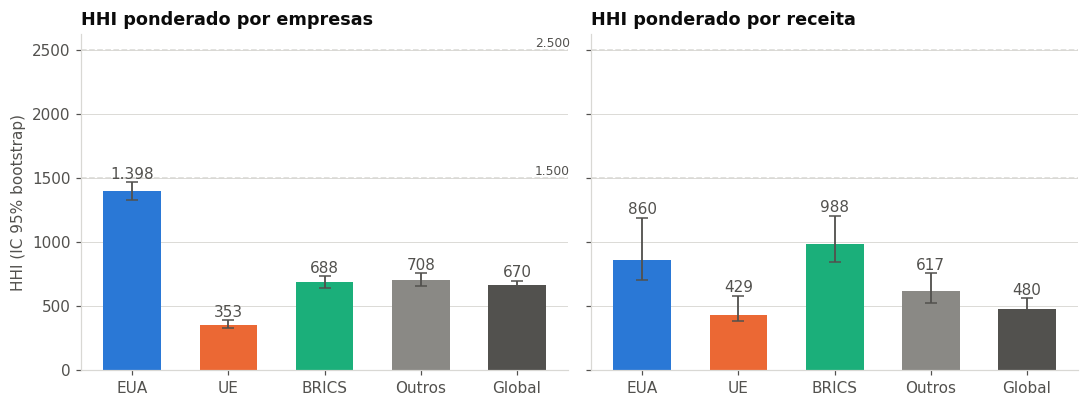

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
order = BLOC_ORDER + ["Global"]
for ax, weight in zip(axes, ["empresas", "receita"]):
    c = conc[conc["peso"] == weight].set_index("bloco").reindex(order)
    err = np.vstack([c["hhi"] - c["hhi_lo"], c["hhi_hi"] - c["hhi"]])
    ax.bar(order, c["hhi"], yerr=err, capsize=4, color=[BLOC_COLOR[b] for b in order], width=0.6, error_kw=dict(ecolor=INK2, lw=1.2))
    for i, (v, hi) in enumerate(zip(c["hhi"], c["hhi_hi"])):
        ax.text(i, hi + 25, f"{v:,.0f}".replace(",", "."), ha="center", color=INK2)
    ax.axhline(1500, color=GRID, lw=1, ls="--"); ax.axhline(2500, color=GRID, lw=1, ls="--")
    ax.set_title(f"HHI ponderado por {weight}"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("HHI (IC 95% bootstrap)")
axes[0].text(len(order) - 0.45, 1500, "1.500", va="bottom", ha="right", color=INK2, fontsize=8)
axes[0].text(len(order) - 0.45, 2500, "2.500", va="bottom", ha="right", color=INK2, fontsize=8)
show(fig, "02_hhi_por_bloco")

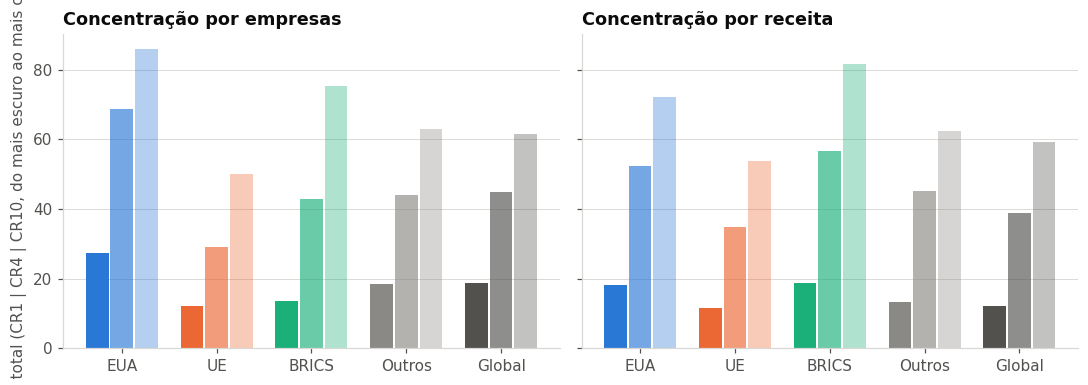

peso,empresas,receita
N efetivo,,
EUA,7.2,11.6
UE,28.3,23.3
BRICS,14.5,10.1
Outros,14.1,16.2
Global,14.9,20.8


In [32]:
# CR1 / CR4 / CR10 e N efetivo por bloco
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
x = np.arange(len(order)); wbar = 0.26
for ax, weight in zip(axes, ["empresas", "receita"]):
    c = conc[conc["peso"] == weight].set_index("bloco").reindex(order)
    for k, (col, alpha) in enumerate([("cr1", 1.0), ("cr4", 0.65), ("cr10", 0.35)]):
        ax.bar(x + (k - 1) * wbar, c[col] * 100, wbar - 0.02, color=[BLOC_COLOR[b] for b in order], alpha=alpha,
               label=col.upper() if ax is axes[0] else None)
    ax.set_xticks(x, order); ax.set_title(f"Concentração por {weight}"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% do total (CR1 | CR4 | CR10, do mais escuro ao mais claro)")
show(fig, "02_cr_por_bloco")
conc.pivot(index="bloco", columns="peso", values="n_efetivo").reindex(order).round(1).rename_axis("N efetivo")

## 3. Principais provedores por bloco

Barras = **cobertura** (% das empresas, ou da receita, do bloco que usam o provedor).

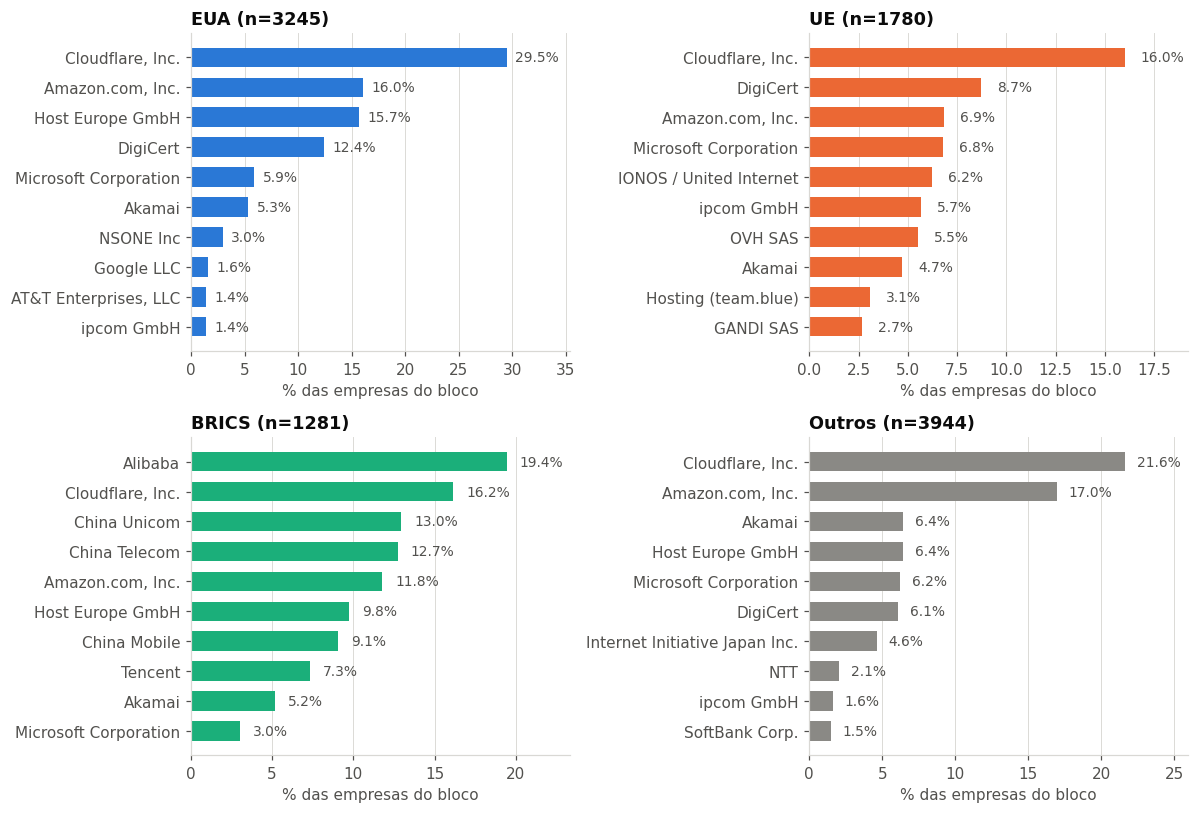

In [33]:
def coverage(d, weight):
    if weight == "empresas":
        return d.groupby("unit")["rank"].nunique() / d["rank"].nunique()
    tot = d.drop_duplicates("rank")["revenue_ttm"].sum()
    return d.groupby("unit")["revenue_ttm"].sum() / tot


def top_panels(weight, name, k=10):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
    for ax, b in zip(axes.ravel(), BLOC_ORDER):
        cv = coverage(dep[dep["bloc"] == b], weight).sort_values(ascending=False).head(k)[::-1] * 100
        ax.barh([trunc(i, 32) for i in cv.index], cv.values, color=BLOC_COLOR[b], height=0.65)
        for i, v in enumerate(cv.values):
            ax.text(v + 0.8, i, f"{v:.1f}%", va="center", color=INK2, fontsize=9)
        ax.set_title(f"{b} (n={dep[dep['bloc'] == b]['rank'].nunique()})")
        ax.set_xlim(0, max(cv.max() * 1.2, 5)); ax.grid(axis="y", visible=False); ax.set_xlabel(f"% das {weight} do bloco")
    show(fig, name)


top_panels("empresas", "03_top_provedores_empresas")

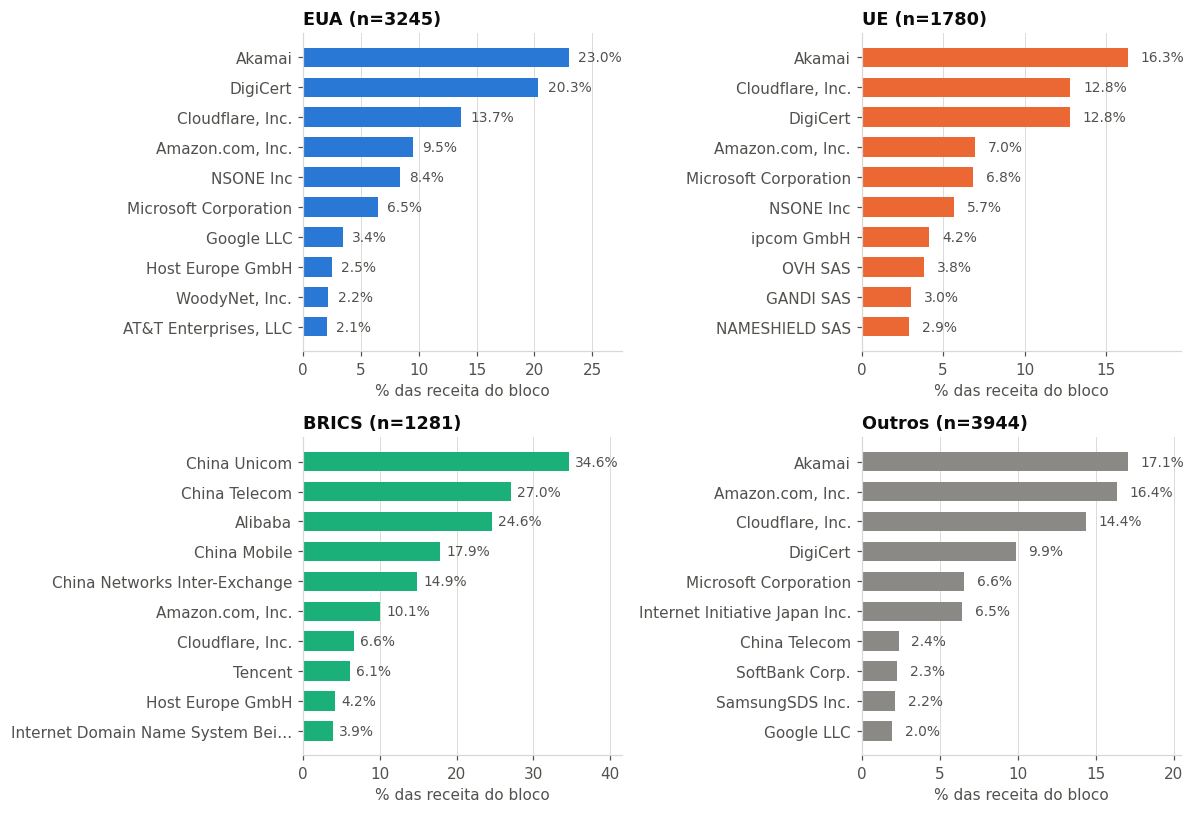

In [34]:
top_panels("receita", "03_top_provedores_receita")

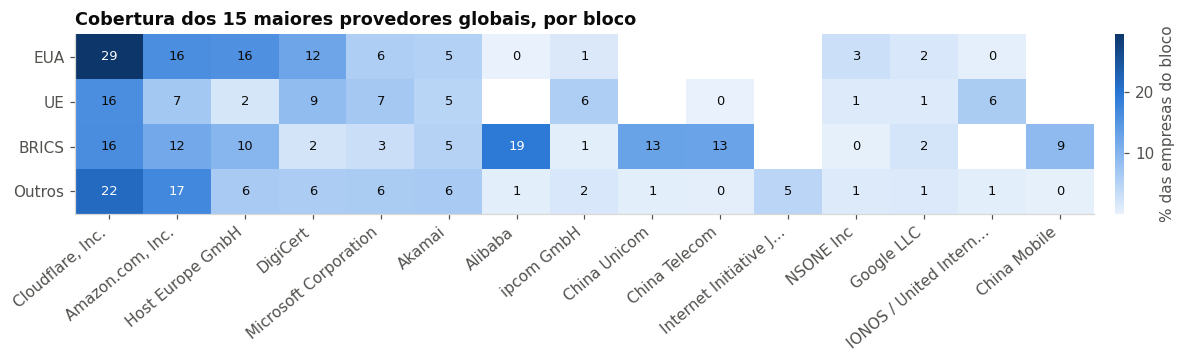

In [35]:
# Heatmap: cobertura (% das empresas do bloco) dos 15 maiores provedores globais
def heat(ax, M, fmt="{:.0f}", vmin=None, vmax=None, cmap=SEQ, xlabels=None, ylabels=None, cbar_label=None, fig=None):
    im = ax.imshow(M.values.astype(float), aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(M.shape[1]), xlabels if xlabels is not None else M.columns, rotation=40, ha="right")
    ax.set_yticks(range(M.shape[0]), ylabels if ylabels is not None else M.index)
    ax.grid(False)
    lo, hi = np.nanmin(M.values.astype(float)), np.nanmax(M.values.astype(float))
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.iat[i, j]
            if pd.notna(v):
                dark = (float(v) - lo) / (hi - lo + 1e-12) > 0.55
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8.5, color="white" if dark else INK)
    if cbar_label and fig is not None:
        cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02); cb.set_label(cbar_label); cb.outline.set_visible(False)
    return im


glob_top = coverage(dep, "empresas").sort_values(ascending=False).head(15).index
M = pd.DataFrame({b: coverage(dep[dep["bloc"] == b], "empresas").reindex(glob_top) * 100 for b in BLOC_ORDER}).T
fig, ax = plt.subplots(figsize=(11, 3.4))
heat(ax, M, "{:.0f}", xlabels=[trunc(c, 22) for c in glob_top], cbar_label="% das empresas do bloco", fig=fig)
ax.set_title("Cobertura dos 15 maiores provedores globais, por bloco")
show(fig, "03_heatmap_provedores_bloco")

## 4. Curvas de concentração

**Lorenz** (distância à diagonal = desigualdade entre provedores; **Gini** na legenda) e **Pareto** (quantos provedores cobrem X% das dependências).

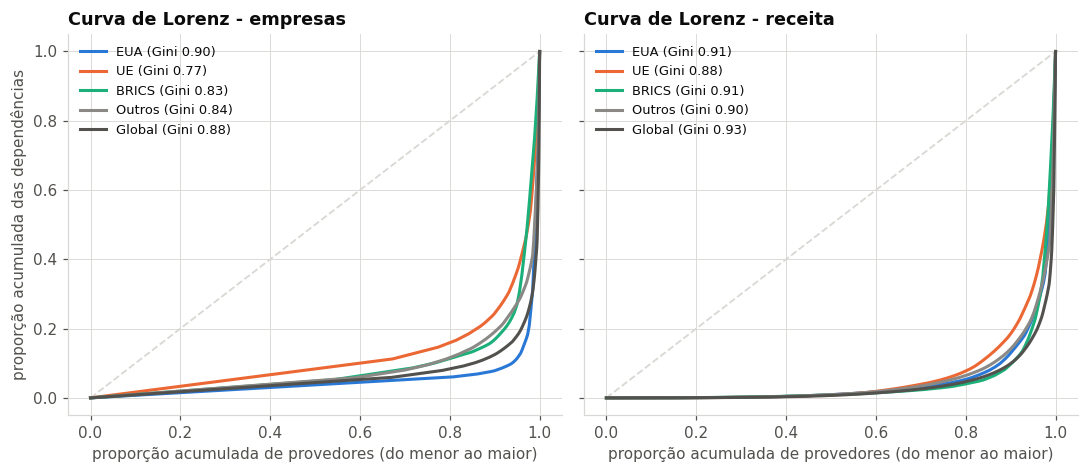

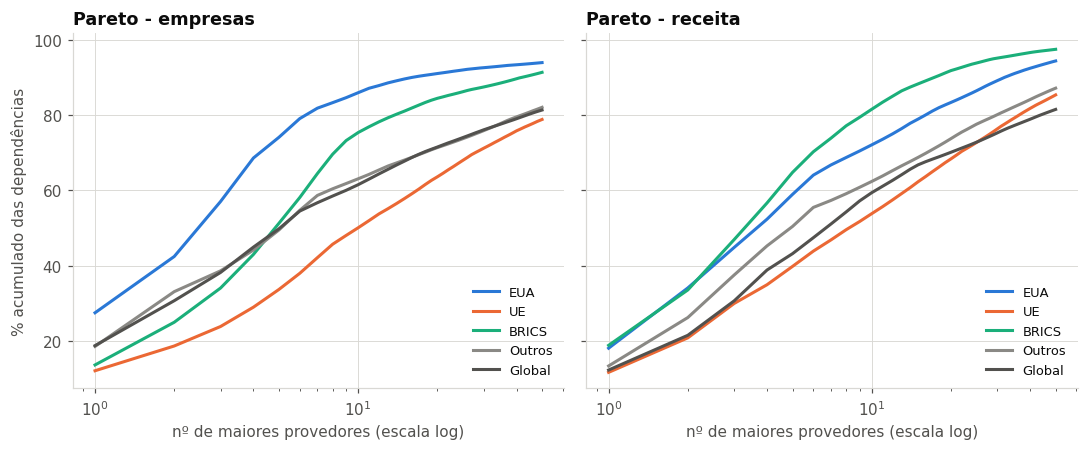

peso,empresas,receita
bloco,,
EUA,0.899,0.905
UE,0.766,0.878
BRICS,0.826,0.912
Outros,0.837,0.901
Global,0.877,0.927


In [36]:
def lorenz(s):
    v = np.sort(s.values)
    y = np.insert(np.cumsum(v) / v.sum(), 0, 0.0)
    x = np.linspace(0, 1, len(y))
    gini = 1 - 2 * np.sum((y[1:] + y[:-1]) / 2 * np.diff(x))
    return x, y, gini


fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
gini_rows = []
for ax, weight in zip(axes, ["empresas", "receita"]):
    ax.plot([0, 1], [0, 1], color=GRID, lw=1.2, ls="--")
    for b, d in groups(dep).items():
        x, y, g = lorenz(shares(d, weight))
        ax.plot(x, y, color=BLOC_COLOR[b], lw=2, label=f"{b} (Gini {g:.2f})")
        gini_rows.append({"bloco": b, "peso": weight, "gini": g})
    ax.set_title(f"Curva de Lorenz - {weight}"); ax.set_xlabel("proporção acumulada de provedores (do menor ao maior)")
    ax.legend(loc="upper left", fontsize=8.5)
axes[0].set_ylabel("proporção acumulada das dependências")
show(fig, "04_lorenz")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, weight in zip(axes, ["empresas", "receita"]):
    for b, d in groups(dep).items():
        s = shares(d, weight).values
        k = np.arange(1, min(len(s), 50) + 1)
        ax.plot(k, np.cumsum(s)[: len(k)] * 100, color=BLOC_COLOR[b], lw=2, label=b)
    ax.set_xscale("log"); ax.set_xlabel("nº de maiores provedores (escala log)"); ax.set_title(f"Pareto - {weight}")
    ax.legend(loc="lower right", fontsize=8.5)
axes[0].set_ylabel("% acumulado das dependências")
show(fig, "04_pareto")
pd.DataFrame(gini_rows).pivot(index="bloco", columns="peso", values="gini").reindex(order).round(3)

## 5. Jurisdição dos provedores (soberania)

Para cada bloco de empresas: **onde estão (país de registro) os provedores de que dependem?**
Leitura: a linha "UE" na coluna "EUA" é a fração das dependências das empresas europeias atendidas por organizações americanas.
`Outros` como provedor agrega todos os demais países; `Desconhecido` = organização sem país no AS2Org.

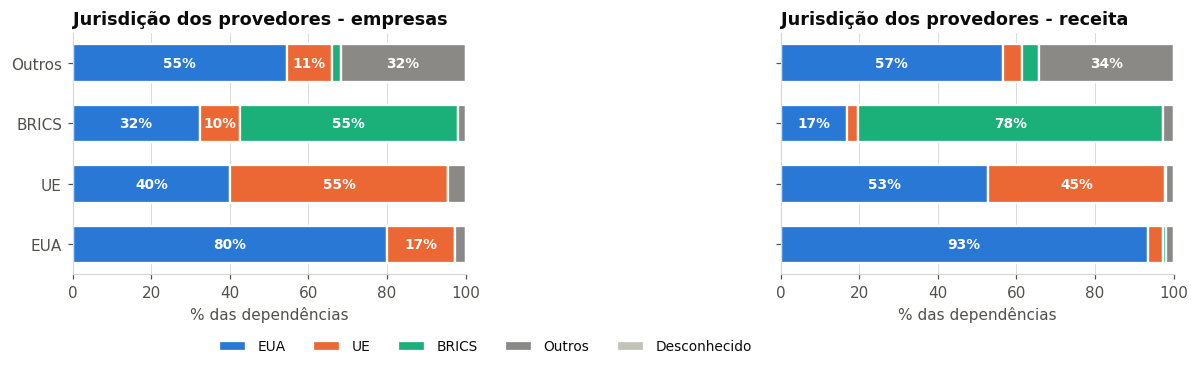

empresas                                 receita              \
provider_bloc      EUA    UE BRICS Outros Desconhecido     EUA    UE BRICS   
bloc                                                                         
EUA               80.0  17.2   0.1    2.7          0.0    93.5   3.9   0.6   
UE                40.1  55.4   0.1    4.4          0.0    52.9  45.0   0.2   
BRICS             32.3  10.2  55.5    2.0          0.0    16.9   2.8  77.7   
Outros            54.5  11.4   2.2   31.8          0.0    56.5   5.0   4.2   

                                   
provider_bloc Outros Desconhecido  
bloc                               
EUA              2.0          0.0  
UE               1.9          0.0  
BRICS            2.6          0.0  
Outros          34.3          0.0

In [37]:
PB_ORDER = ["EUA", "UE", "BRICS", "Outros", "Desconhecido"]


def jurisdiction_matrix(weight):
    w = dep["revenue_ttm"] if weight == "receita" else pd.Series(1.0, index=dep.index)
    m = (dep.assign(w=w).pivot_table(index="bloc", columns="provider_bloc", values="w", aggfunc="sum", fill_value=0)
            .reindex(index=BLOC_ORDER, columns=PB_ORDER, fill_value=0))
    return m.div(m.sum(axis=1), axis=0) * 100


J = {w: jurisdiction_matrix(w) for w in ["empresas", "receita"]}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, weight in zip(axes, ["empresas", "receita"]):
    m = J[weight]
    left = np.zeros(len(m))
    for pb in PB_ORDER:
        ax.barh(m.index, m[pb], left=left, color=BLOC_COLOR[pb], edgecolor="white", linewidth=1.5, label=pb, height=0.62)
        for i, (l, v) in enumerate(zip(left, m[pb])):
            if v >= 6:
                ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        left += m[pb].values
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_title(f"Jurisdição dos provedores - {weight}")
    ax.set_xlabel("% das dependências"); ax.grid(axis="y", visible=False)
axes[0].legend(ncol=5, loc="upper center", bbox_to_anchor=(1.05, -0.22), fontsize=9)
show(fig, "05_jurisdicao_provedores")
pd.concat(J, axis=1).round(1)

In [38]:
# Indicadores por empresa: dependência dos EUA e autossuficiência jurisdicional
dep["is_us"] = dep["provider_bloc"] == "EUA"
dep["is_own"] = dep["provider_bloc"] == dep["bloc"]
g = dep.groupby("rank")
flags = pd.DataFrame({
    "any_us": g["is_us"].any(), "all_us": g["is_us"].all(), "all_own": g["is_own"].all(), "any_own": g["is_own"].any(),
    "n_prov": g["unit"].nunique(),
}).join(comp[["bloc", "revenue_ttm", "sector", "company_country"]])


def pct(flag_col, d=flags):
    rows = {}
    for b in BLOC_ORDER + ["Global"]:
        s = d if b == "Global" else d[d["bloc"] == b]
        rows[b] = {"% empresas": s[flag_col].mean() * 100,
                   "% receita": s.loc[s[flag_col], "revenue_ttm"].sum() / s["revenue_ttm"].sum() * 100}
    return pd.DataFrame(rows).T


ind = pd.concat({"≥1 provedor nos EUA": pct("any_us"), "100% em provedores dos EUA": pct("all_us"),
                 "≥1 provedor no próprio bloco": pct("any_own"), "100% no próprio bloco": pct("all_own")}, axis=1)
ind.loc["Outros", [c for c in ind.columns if "próprio bloco" in c[0]]] = np.nan   # "Outros" não é uma jurisdição única
ind.round(1)

≥1 provedor nos EUA           100% em provedores dos EUA            \
                % empresas % receita                 % empresas % receita   
EUA                   80.7      95.2                       80.1      94.0   
UE                    51.5      70.5                       40.7      52.2   
BRICS                 44.5      29.6                       40.3      20.9   
Outros                62.0      67.8                       56.2      54.8   
Global                63.9      72.4                       59.1      63.6   

       ≥1 provedor no próprio bloco           100% no próprio bloco            
                         % empresas % receita            % empresas % receita  
EUA                            80.7      95.2                  80.1      94.0  
UE                             57.8      46.7                  45.0      27.8  
BRICS                          45.0      71.2                  41.2      62.6  
Outros                          NaN       NaN                   NaN       NaN  
Global                         53.5      65.9                  48.1      57.4

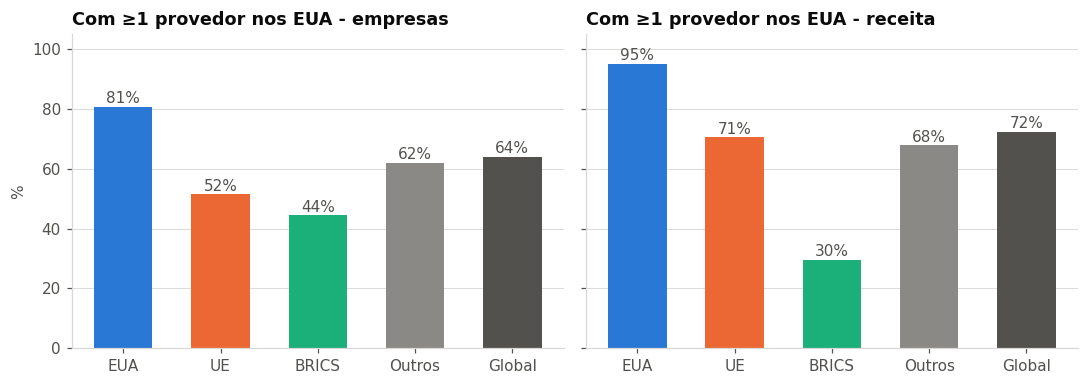

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
us = pct("any_us").reindex(order)
for ax, col in zip(axes, ["% empresas", "% receita"]):
    ax.bar(order, us[col], color=[BLOC_COLOR[b] for b in order], width=0.6)
    for i, v in enumerate(us[col]):
        ax.text(i, v + 1.2, f"{v:.0f}%", ha="center", color=INK2)
    ax.set_ylim(0, 105); ax.set_title(f"Com ≥1 provedor nos EUA - {col.replace('% ', '')}"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("%")
show(fig, "05_dependencia_eua")

## 6. Setor × bloco

HHI dentro de cada setor **do bloco** (só recortes com ≥ `MIN_N` empresas). Compare colunas para ver quais setores são mais concentrados
em cada bloco, e linhas para ver como o mesmo setor se comporta entre blocos.

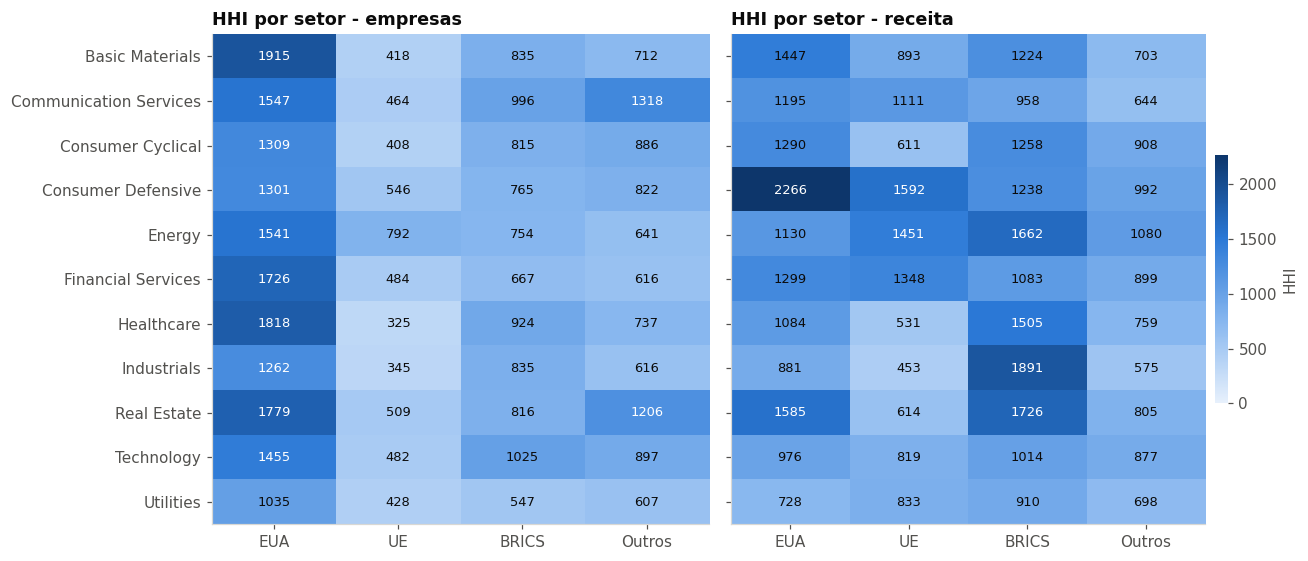

nº de empresas por recorte (somente ≥ MIN_N):


bloco,EUA,UE,BRICS,Outros
setor,,,,
Basic Materials,116,95,146,365
Communication Services,149,135,103,249
Consumer Cyclical,361,235,199,467
Consumer Defensive,147,105,88,276
Energy,149,42,33,185
Financial Services,542,205,195,567
Healthcare,557,170,92,256
Industrials,452,383,191,741
Real Estate,201,127,40,294


In [40]:
rows = []
for (b, s), d in dep.groupby(["bloc", "sector"]):
    n = d["rank"].nunique()
    if n < MIN_N:
        continue
    for weight in ["empresas", "receita"]:
        m = metrics(shares(d, weight))
        top = shares(d, weight).index[0]
        rows.append({"bloco": b, "setor": s, "peso": weight, "n_empresas": n, "hhi": m["hhi"], "cr1": m["cr1"], "top1": top})
sec = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
for ax, weight in zip(axes, ["empresas", "receita"]):
    M = (sec[sec["peso"] == weight].pivot(index="setor", columns="bloco", values="hhi")
            .reindex(columns=BLOC_ORDER))
    heat(ax, M, "{:.0f}", vmin=0, vmax=sec["hhi"].max(), fig=fig if ax is axes[1] else None, cbar_label="HHI")
    ax.set_title(f"HHI por setor - {weight}")
    ax.set_xticks(range(len(BLOC_ORDER)), BLOC_ORDER, rotation=0, ha="center")
show(fig, "06_hhi_setor_bloco")

n_tab = sec[sec["peso"] == "empresas"].pivot(index="setor", columns="bloco", values="n_empresas").reindex(columns=BLOC_ORDER)
print("nº de empresas por recorte (somente ≥ MIN_N):")
n_tab

In [41]:
# Provedor nº 1 de cada setor em cada bloco (participação por empresas)
top_tab = (sec[sec["peso"] == "empresas"]
           .assign(txt=lambda t: t["top1"].map(lambda x: trunc(x, 24)) + " (" + (t["cr1"] * 100).round(0).astype(int).astype(str) + "%)")
           .pivot(index="setor", columns="bloco", values="txt").reindex(columns=BLOC_ORDER))
top_tab

bloco,EUA,UE,BRICS,Outros
setor,,,,
Basic Materials,"Cloudflare, Inc. (36%)","Cloudflare, Inc. (11%)",Host Europe GmbH (16%),"Cloudflare, Inc. (20%)"
Communication Services,"Amazon.com, Inc. (30%)","Cloudflare, Inc. (13%)",China Unicom (15%),"Amazon.com, Inc. (32%)"
Consumer Cyclical,"Cloudflare, Inc. (26%)","Cloudflare, Inc. (12%)","Cloudflare, Inc. (16%)","Amazon.com, Inc. (21%)"
Consumer Defensive,"Cloudflare, Inc. (24%)","Cloudflare, Inc. (14%)",Alibaba (17%),"Cloudflare, Inc. (21%)"
Energy,Host Europe GmbH (29%),"Cloudflare, Inc. (20%)",China Unicom (13%),"Cloudflare, Inc. (16%)"
Financial Services,"Cloudflare, Inc. (36%)",Akamai (14%),China Unicom (12%),"Cloudflare, Inc. (17%)"
Healthcare,"Cloudflare, Inc. (29%)","Cloudflare, Inc. (9%)",Alibaba (20%),"Cloudflare, Inc. (19%)"
Industrials,"Cloudflare, Inc. (27%)","Cloudflare, Inc. (10%)",Alibaba (16%),"Cloudflare, Inc. (17%)"
Real Estate,"Cloudflare, Inc. (29%)","Cloudflare, Inc. (16%)","Cloudflare, Inc. (21%)","Cloudflare, Inc. (29%)"


## 7. Porte × bloco

Quartis de receita calculados **sobre a amostra global** (os mesmos cortes para todos os blocos, para comparabilidade).
Pergunta: empresas maiores terceirizam mais, ou concentram-se mais em poucos provedores?

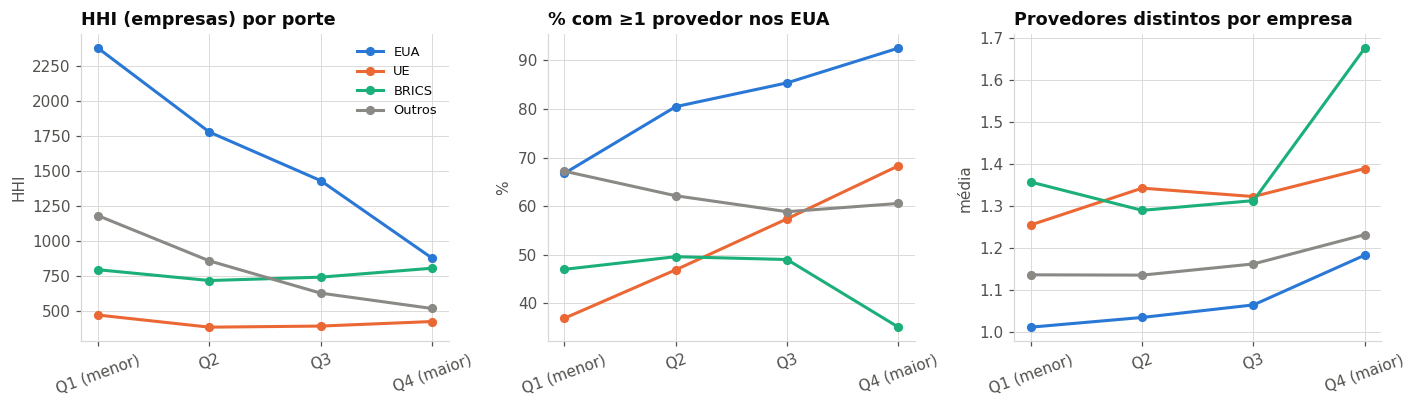

,bloco,porte,n_empresas,hhi,pct_us,provedores_por_empresa
0,BRICS,Q1 (menor),213,796.8,46.9,1.4
1,BRICS,Q2,335,719.6,49.6,1.3
2,BRICS,Q3,339,743.7,49.0,1.3
3,BRICS,Q4 (maior),394,807.4,35.0,1.7
4,EUA,Q1 (menor),923,2380.5,66.7,1.0
5,EUA,Q2,743,1780.7,80.5,1.0
6,EUA,Q3,787,1433.5,85.4,1.1
7,EUA,Q4 (maior),792,880.1,92.6,1.2
8,Outros,Q1 (menor),917,1183.2,67.2,1.1
9,Outros,Q2,1040,860.3,62.1,1.1


In [42]:
QL = ["Q1 (menor)", "Q2", "Q3", "Q4 (maior)"]
comp_in = comp.loc[dep["rank"].unique()].copy()
comp_in["porte"] = pd.qcut(comp_in["revenue_ttm"], 4, labels=QL)
dep = dep.drop(columns=[c for c in ["porte"] if c in dep]).join(comp_in["porte"], on="rank")
flags = flags.drop(columns=[c for c in ["porte"] if c in flags]).join(comp_in["porte"])

rows = []
for (b, q), d in dep.groupby(["bloc", "porte"], observed=True):
    n = d["rank"].nunique()
    if n < MIN_N:
        continue
    f = flags[(flags["bloc"] == b) & (flags["porte"] == q)]
    rows.append({"bloco": b, "porte": q, "n_empresas": n, "hhi": metrics(shares(d, "empresas"))["hhi"],
                 "pct_us": f["any_us"].mean() * 100, "provedores_por_empresa": f["n_prov"].mean()})
size = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (col, ttl, yl) in zip(axes, [("hhi", "HHI (empresas) por porte", "HHI"),
                                    ("pct_us", "% com ≥1 provedor nos EUA", "%"),
                                    ("provedores_por_empresa", "Provedores distintos por empresa", "média")]):
    for b in BLOC_ORDER:
        s = size[size["bloco"] == b].set_index("porte").reindex(QL)
        ax.plot(QL, s[col], color=BLOC_COLOR[b], lw=2, marker="o", ms=5, label=b)
    ax.set_title(ttl); ax.set_ylabel(yl); ax.tick_params(axis="x", rotation=20)
axes[0].legend(fontsize=8.5)
show(fig, "07_porte_bloco")
size.round(1)

## 8. Resiliência e risco sistêmico

1. **Redundância**: nº de provedores distintos por empresa (1 = ponto único de falha).
2. **Simulação de falha**: se os *k* maiores provedores **globais** saíssem do ar, que fração das empresas/receita de cada bloco teria
   *alguma* dependência afetada e que fração ficaria *totalmente* dependente deles.

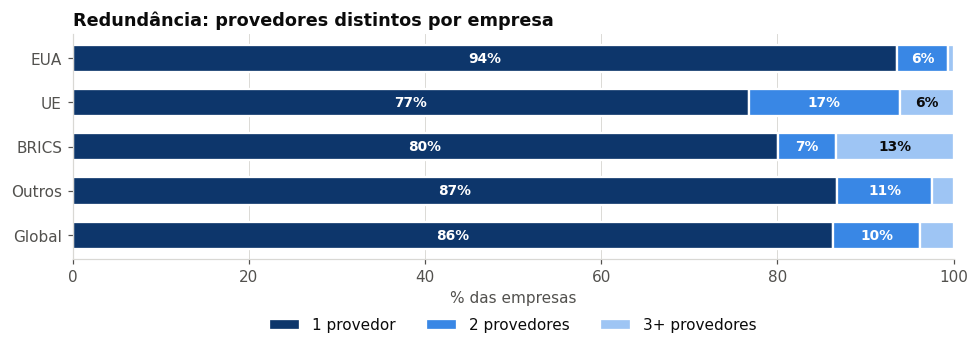

,1 provedor,2 provedores,3+ provedores
EUA,93.6,5.8,0.6
UE,76.7,17.2,6.1
BRICS,80.0,6.6,13.3
Outros,86.8,10.8,2.4
Global,86.3,9.8,3.8


In [43]:
fig, ax = plt.subplots(figsize=(9, 3.4))
cats = [("1 provedor", "#0d366b"), ("2 provedores", "#3987e5"), ("3+ provedores", "#9ec5f4")]
tab = {}
for b in BLOC_ORDER + ["Global"]:
    s = flags if b == "Global" else flags[flags["bloc"] == b]
    tab[b] = {"1 provedor": (s["n_prov"] == 1).mean() * 100, "2 provedores": (s["n_prov"] == 2).mean() * 100,
              "3+ provedores": (s["n_prov"] >= 3).mean() * 100}
tab = pd.DataFrame(tab).T.reindex(order)
left = np.zeros(len(tab))
for c, col in cats:
    ax.barh(tab.index, tab[c], left=left, color=col, edgecolor="white", linewidth=1.5, label=c, height=0.62)
    for i, (l, v) in enumerate(zip(left, tab[c])):
        if v >= 5:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, fontweight="bold",
                    color="white" if col != "#9ec5f4" else INK)
    left += tab[c].values
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_title("Redundância: provedores distintos por empresa"); ax.set_xlabel("% das empresas")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
show(fig, "08_redundancia")
tab.round(1)

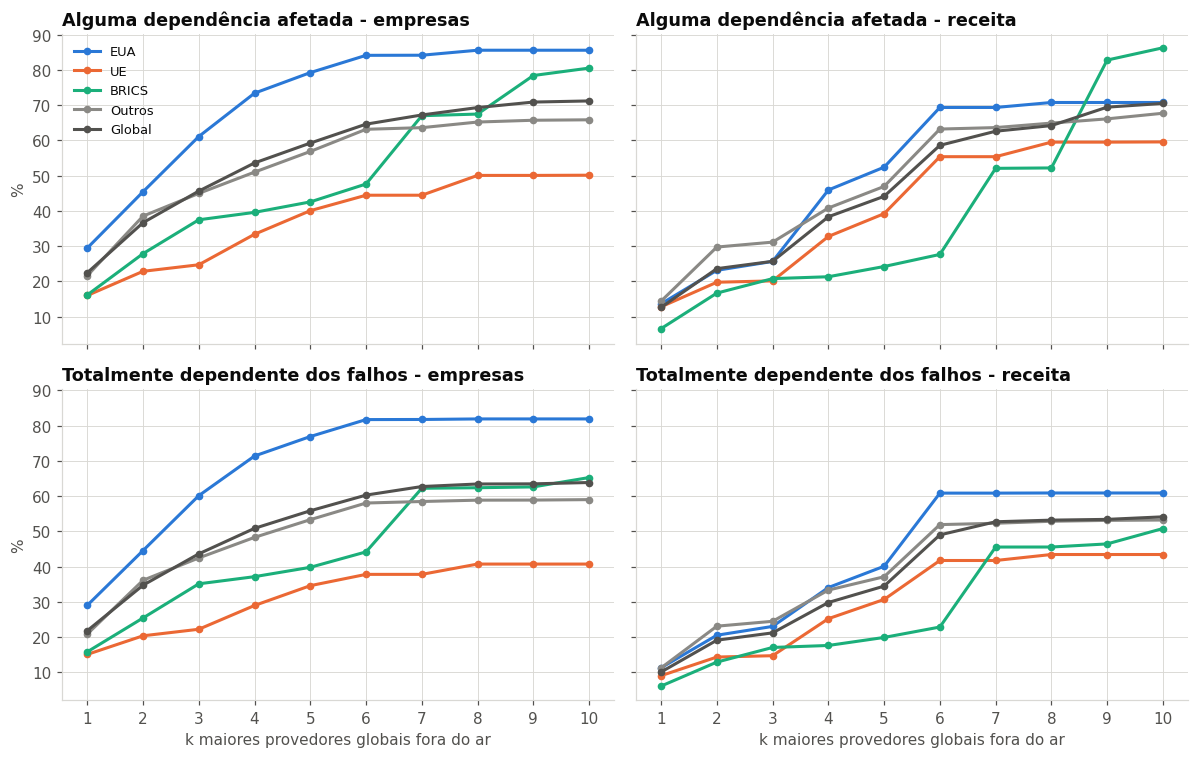

% empresas % receita
tipo            all       all
k bloco                      
1 BRICS        15.8       6.1
  EUA          29.0      11.3
  Global       21.8      10.1
  Outros       20.9      11.3
  UE           15.1       9.1
3 BRICS        35.1      17.1
  EUA          60.1      23.1
  Global       43.6      21.2
  Outros       42.5      24.5
  UE           22.2      14.8
5 BRICS        39.8      19.9
  EUA          76.9      40.1
  Global       55.8      34.5
  Outros       53.3      37.1
  UE           34.6      30.7

In [44]:
glob_rank = coverage(dep, "empresas").sort_values(ascending=False).index
K = range(1, 11)
res = []
for k in K:
    failed = set(glob_rank[:k])
    dd = dep.assign(f=dep["unit"].isin(failed))
    gg = dd.groupby("rank")["f"].agg(["any", "all"]).join(comp[["bloc", "revenue_ttm"]])
    for b in BLOC_ORDER + ["Global"]:
        s = gg if b == "Global" else gg[gg["bloc"] == b]
        for kind in ["any", "all"]:
            res.append({"k": k, "bloco": b, "tipo": kind,
                        "% empresas": s[kind].mean() * 100,
                        "% receita": s.loc[s[kind], "revenue_ttm"].sum() / s["revenue_ttm"].sum() * 100})
res = pd.DataFrame(res)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for (r, kind), (c, col) in [((r, kind), (c, col)) for r, kind in enumerate(["any", "all"]) for c, col in enumerate(["% empresas", "% receita"])]:
    ax = axes[r, c]
    for b in BLOC_ORDER + ["Global"]:
        s = res[(res["bloco"] == b) & (res["tipo"] == kind)]
        ax.plot(s["k"], s[col], color=BLOC_COLOR[b], lw=2, marker="o", ms=4, label=b)
    ax.set_title(("Alguma dependência afetada" if kind == "any" else "Totalmente dependente dos falhos") + f" - {col.replace('% ', '')}")
    ax.set_xticks(list(K))
for ax in axes[1]:
    ax.set_xlabel("k maiores provedores globais fora do ar")
for ax in axes[:, 0]:
    ax.set_ylabel("%")
axes[0, 0].legend(fontsize=8.5)
show(fig, "08_simulacao_falha")
res[(res["k"].isin([1, 3, 5])) & (res["tipo"] == "all")].pivot(index=["k", "bloco"], columns="tipo", values=["% empresas", "% receita"]).round(1)

## 9. Empresas vs receita

Provedores acima da diagonal atendem proporcionalmente **mais receita** do que empresas (servem as grandes);
abaixo, atendem muitas empresas pequenas. Uma tabela por bloco lista os maiores desvios.

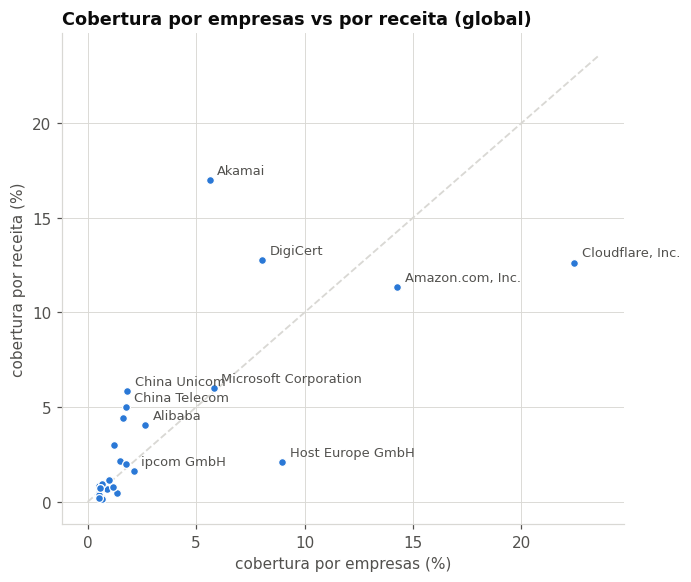

,unit,empresas,receita,razao_receita_empresas,bloco
0,"Cloudflare, Inc.",29.46,13.66,0.46,EUA
1,"Amazon.com, Inc.",16.02,9.53,0.59,EUA
2,Host Europe GmbH,15.65,2.52,0.16,EUA
3,DigiCert,12.39,20.33,1.64,EUA
4,Microsoft Corporation,5.89,6.50,1.10,EUA
5,Akamai,5.33,22.97,4.31,EUA
6,NSONE Inc,2.96,8.37,2.83,EUA
0,"Cloudflare, Inc.",16.01,12.80,0.80,UE
1,DigiCert,8.71,12.76,1.47,UE
2,"Amazon.com, Inc.",6.85,6.97,1.02,UE


In [45]:
ce, cr_ = coverage(dep, "empresas") * 100, coverage(dep, "receita") * 100
sc = pd.DataFrame({"empresas": ce, "receita": cr_}).dropna()
sc = sc[sc["empresas"] >= 0.5]

fig, ax = plt.subplots(figsize=(6.4, 5.4))
lim = max(sc.max()) * 1.05
ax.plot([0, lim], [0, lim], color=GRID, lw=1.2, ls="--")
ax.scatter(sc["empresas"], sc["receita"], s=26, color=BLOC_COLOR["EUA"], edgecolor="white", linewidth=0.8, zorder=3)
for name, r in sc.sort_values("empresas", ascending=False).head(10).iterrows():
    ax.annotate(trunc(name, 24), (r["empresas"], r["receita"]), xytext=(5, 4), textcoords="offset points", fontsize=8.5, color=INK2)
ax.set_xlabel("cobertura por empresas (%)"); ax.set_ylabel("cobertura por receita (%)")
ax.set_title("Cobertura por empresas vs por receita (global)")
show(fig, "09_empresas_vs_receita")

rows = []
for b in BLOC_ORDER:
    d = dep[dep["bloc"] == b]
    t = pd.DataFrame({"empresas": coverage(d, "empresas") * 100, "receita": coverage(d, "receita") * 100})
    t = t[t["empresas"] >= 2]
    t["razao_receita_empresas"] = t["receita"] / t["empresas"]
    t["bloco"] = b
    rows.append(t.sort_values("empresas", ascending=False).head(8).reset_index())
pd.concat(rows).round(2)

## 10. IPv4 vs IPv6

A população IPv6 é menor (só quem publica AAAA). Barras hachuradas = IPv6.

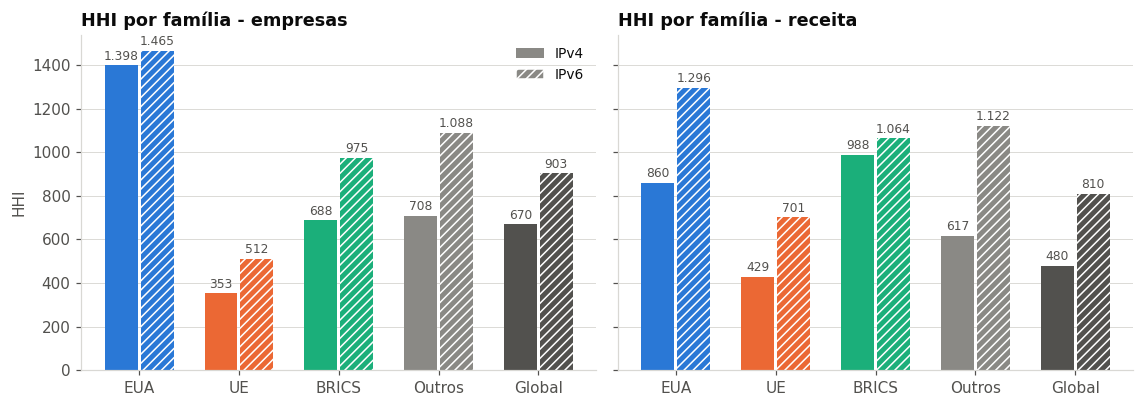

,empresas c/ IPv4,empresas c/ IPv6,% com IPv6
bloc,,,
EUA,3245,2736,84.3
UE,1780,1464,82.2
BRICS,1281,1025,80.0
Outros,3944,2927,74.2


In [46]:
d4, d6 = dep_for("A", LAYER), dep_for("AAAA", LAYER)
rows = []
for fam, d in [("IPv4", d4), ("IPv6", d6)]:
    for b, dd in groups(d).items():
        for weight in ["empresas", "receita"]:
            rows.append({"familia": fam, "bloco": b, "peso": weight, "n_empresas": dd["rank"].nunique(),
                         "hhi": metrics(shares(dd, weight))["hhi"]})
fam = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
x = np.arange(len(order)); wb = 0.36
for ax, weight in zip(axes, ["empresas", "receita"]):
    for k, (f, hatch) in enumerate([("IPv4", None), ("IPv6", "////")]):
        s = fam[(fam["peso"] == weight) & (fam["familia"] == f)].set_index("bloco").reindex(order)
        bars = ax.bar(x + (k - 0.5) * wb, s["hhi"], wb - 0.03, color=[BLOC_COLOR[b] for b in order], hatch=hatch,
                      edgecolor="white" if hatch else "none", linewidth=0, label=f)
        for xi, v in zip(x + (k - 0.5) * wb, s["hhi"]):
            ax.text(xi, v + 25, f"{v:,.0f}".replace(",", "."), ha="center", fontsize=8, color=INK2)
    ax.set_xticks(x, order); ax.set_title(f"HHI por família - {weight}"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("HHI")
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(facecolor="#8a8985", label="IPv4"), Patch(facecolor="#8a8985", hatch="////", edgecolor="white", label="IPv6")], fontsize=9)
show(fig, "10_ipv4_vs_ipv6")

adopt = pd.DataFrame({
    "empresas c/ IPv4": d4.groupby("bloc")["rank"].nunique(), "empresas c/ IPv6": d6.groupby("bloc")["rank"].nunique()
}).reindex(BLOC_ORDER)
adopt["% com IPv6"] = adopt["empresas c/ IPv6"] / adopt["empresas c/ IPv4"] * 100
adopt.round(1)

## 11. Camada DNS (operador `ns_apex`) vs hosting (`as_org`)

O operador do DNS (ex.: Cloudflare, AWS Route 53, Azure DNS) e a rede onde os NS estão hospedados são camadas distintas:
um domínio pode usar DNS gerenciado de um provedor cujos NS estão na rede de outro. Barras hachuradas = operador DNS.

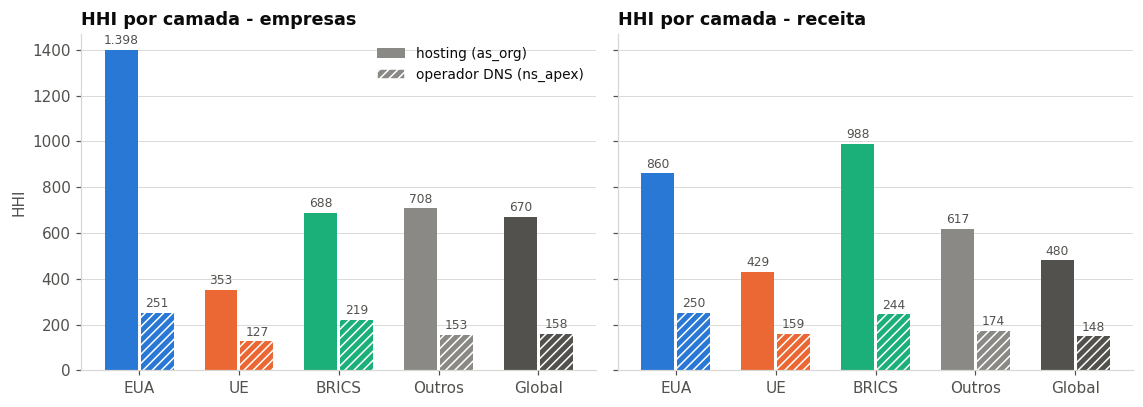

operador DNS  % empresas
EUA    0     cloudflare.com        19.0
       1  domaincontrol.com        14.9
       2       worldnic.com         7.0
       3      azure-dns.com         5.2
       4      azure-dns.org         5.1
UE     0     cloudflare.com        13.3
       1     azure-dns.info         5.4
       2      azure-dns.org         5.4
       3      azure-dns.com         5.4
       4      azure-dns.net         5.4
BRICS  0         alidns.com        11.6
       1     cloudflare.com        11.0
       2  domaincontrol.com         9.8
       3        hichina.com         6.4
       4           akam.net         3.7
Outros 0     cloudflare.com        16.3
       1  domaincontrol.com         6.4
       2           akam.net         5.2
       3      azure-dns.org         4.3
       4     azure-dns.info         4.3

In [ ]:
d_org, d_ns = dep_for(FAMILY, "as_org"), dep_for(FAMILY, "ns_apex")
rows = []
for lay, d in [("hosting (as_org)", d_org), ("operador DNS (ns_apex)", d_ns)]:
    for b, dd in groups(d).items():
        for weight in ["empresas", "receita"]:
            m = metrics(shares(dd, weight))
            rows.append({"camada": lay, "bloco": b, "peso": weight, "hhi": m["hhi"], "cr4": m["cr4"], "n_prov": m["n_prov"]})
lay = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, weight in zip(axes, ["empresas", "receita"]):
    for k, (l, hatch) in enumerate([("hosting (as_org)", None), ("operador DNS (ns_apex)", "////")]):
        s = lay[(lay["peso"] == weight) & (lay["camada"] == l)].set_index("bloco").reindex(order)
        ax.bar(x + (k - 0.5) * wb, s["hhi"], wb - 0.03, color=[BLOC_COLOR[b] for b in order], hatch=hatch,
               edgecolor="white" if hatch else "none", linewidth=0)
        for xi, v in zip(x + (k - 0.5) * wb, s["hhi"]):
            ax.text(xi, v + 25, f"{v:,.0f}".replace(",", "."), ha="center", fontsize=8, color=INK2)
    ax.set_xticks(x, order); ax.set_title(f"HHI por camada - {weight}"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("HHI")
axes[0].legend(handles=[Patch(facecolor="#8a8985", label="hosting (as_org)"),
                        Patch(facecolor="#8a8985", hatch="////", edgecolor="white", label="operador DNS (ns_apex)")], fontsize=9)
show(fig, "11_camadas")

top_ns = {b: (coverage(d_ns[d_ns["bloc"] == b], "empresas").sort_values(ascending=False).head(5) * 100).round(1) for b in BLOC_ORDER}

pd.concat({b: s.rename("% empresas").reset_index().rename(columns={"unit": "operador DNS"}) for b, s in top_ns.items()})

## 12. Exportação e resumo

In [48]:
# --- Exporta tabelas
exports = {
    "composicao_blocos": t1, "concentracao_blocos": conc, "jurisdicao_empresas": J["empresas"], "jurisdicao_receita": J["receita"],
    "indicadores_dependencia": ind, "hhi_setor_bloco": sec, "porte_bloco": size, "simulacao_falha": res,
    "ipv4_vs_ipv6": fam, "camadas_dns_hosting": lay, "empresas_flags": flags.reset_index(),
}
for k, v in exports.items():
    v.to_csv(OUT / f"{k}.csv", index=True if k in {"composicao_blocos", "jurisdicao_empresas", "jurisdicao_receita", "indicadores_dependencia"} else False)
print("tabelas ->", OUT.resolve()); print("figuras ->", FIG.resolve())

# --- Resumo automático (para conferir/atualizar o texto)
print("\nRESUMO (família", FAMILY, "| camada", LAYER, ")")
for b in order:
    ce_ = conc[(conc.bloco == b) & (conc.peso == "empresas")].iloc[0]
    cr_ = conc[(conc.bloco == b) & (conc.peso == "receita")].iloc[0]
    d = dep if b == "Global" else dep[dep["bloc"] == b]
    t = coverage(d, "empresas").sort_values(ascending=False)
    line = (f"- {b:<7} n={int(ce_.n_empresas):>5} | HHI empresas {ce_.hhi:>6.0f} [{ce_.hhi_lo:.0f}-{ce_.hhi_hi:.0f}] "
            f"| HHI receita {cr_.hhi:>6.0f} | top1: {trunc(t.index[0], 26)} ({t.iloc[0] * 100:.0f}% das empresas)")
    if b in ind.index:
        line += f" | ≥1 provedor EUA: {ind.loc[b, ('≥1 provedor nos EUA', '% empresas')]:.0f}%"
    print(line)

tabelas -> C:\Users\fsbertoglio\Documents\GitHub\TCC\data\analysis\blocs
figuras -> C:\Users\fsbertoglio\Documents\GitHub\TCC\data\analysis\blocs\figs

RESUMO (família A | camada as_org )
- EUA     n= 3245 | HHI empresas   1398 [1330-1468] | HHI receita    860 | top1: Cloudflare, Inc. (29% das empresas) | ≥1 provedor EUA: 81%
- UE      n= 1780 | HHI empresas    353 [328-391] | HHI receita    429 | top1: Cloudflare, Inc. (16% das empresas) | ≥1 provedor EUA: 52%
- BRICS   n= 1281 | HHI empresas    688 [645-739] | HHI receita    988 | top1: Alibaba (19% das empresas) | ≥1 provedor EUA: 44%
- Outros  n= 3944 | HHI empresas    708 [661-756] | HHI receita    617 | top1: Cloudflare, Inc. (22% das empresas) | ≥1 provedor EUA: 62%
- Global  n=10250 | HHI empresas    670 [644-700] | HHI receita    480 | top1: Cloudflare, Inc. (22% das empresas) | ≥1 provedor EUA: 64%
